# ATUS socializing and communicating trends

## Goal

Reproduce the displayed results from distributed local inputs, without downloading data. Run every cell in order. Numerical statements are computed in the result cells; none are hard-coded.

## Setup

Use the project's Python environment. Start Jupyter inside this repository or set `ECONHACK_REPO` explicitly. The first cell runs `python -m econhack.cli verify` before reading data. The CLI checks source and processed manifests; tables and PNGs receive separate byte-hash receipts below. No acquisition functions or model `run()` entrypoints are called.

In [1]:
import hashlib
import importlib
import inspect
import io
import json
import os
from pathlib import Path
import subprocess
import sys

def find_repository():
    explicit = os.environ.get("ECONHACK_REPO")
    candidates = [Path(explicit).expanduser().resolve()] if explicit else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "src/econhack/cli.py").is_file() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook inside the repository, or set ECONHACK_REPO to its root.")

ROOT = find_repository()
os.environ["ECONHACK_OFFLINE"] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT / "src"))
environment = os.environ.copy()
environment["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + environment.get("PYTHONPATH", "")
verification = subprocess.run(
    [sys.executable, "-m", "econhack.cli", "verify"], cwd=ROOT, env=environment,
    capture_output=True, text=True, check=True,
)
print(verification.stdout.strip())
print(f"Repository: {ROOT.name}\nPython: {sys.version.split()[0]}\nMode: local files only")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display

pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=["#176b87", "#b85c38"])})
PROCESSED = ROOT / "data/processed"
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
input_receipts = []
processed_manifest = json.loads((ROOT / "data/processed_manifest.json").read_text())

def local_file(relative):
    path = (ROOT / relative).resolve()
    if ROOT not in path.parents or not path.is_file():
        raise FileNotFoundError(f"Required local input missing: {relative}. Run the project pipeline and snapshot first.")
    return path

def receipt(path):
    relative = str(path.relative_to(ROOT))
    input_receipts.append({"path": relative, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})

def read_csv(relative, **kwargs):
    path = local_file(relative)
    if str(path.relative_to(ROOT)).startswith("data/processed/") and str(path.relative_to(ROOT)) not in processed_manifest:
        raise ValueError(f"Processed input is not in the verified manifest: {relative}. Run cli snapshot first.")
    receipt(path)
    return pd.read_csv(path, **kwargs)

def read_json(relative):
    path = local_file(relative)
    receipt(path)
    return json.loads(path.read_text())

def show_png(name, required=True):
    path = FIGURES / f"{name}.png"
    if not path.is_file() and not required:
        display(Markdown(f"Figure `{name}.png` was not produced; consult the model status and estimability table."))
        return
    path = local_file(str(path.relative_to(ROOT)))
    receipt(path)
    display(Image(data=path.read_bytes(), format="png", embed=True, width=1000))

def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue(), format="png", embed=True, width=1000))

def show_source(module_name, names):
    module = importlib.import_module(module_name)
    display(Markdown(f"Source: `src/{module_name.replace('.', '/')}.py`. Functions below are displayed, not invoked."))
    for name in names:
        display(Code(inspect.getsource(getattr(module, name)), language="python"))

def show_status(name):
    statuses = read_json("outputs/model_status.json")
    display(pd.DataFrame([{key: value for key, value in statuses.get(name, {"status": "not_run"}).items()
                           if key in {"status", "reason", "n", "updated_utc", "formula", "input_mode"}}]))

Verified 38 source/extract hashes; 0 large source files omitted from distribution.
Repository: econhackathon2026
Python: 3.13.7
Mode: local files only


## Context and methods

The preferred microdata outcome is primary-activity T120101 for ages 15–24 and all ages 15+, using final survey weights and including zero-time diaries. A separate official published-series fallback covers all persons 15+ and a broader published socializing aggregate. It cannot substitute for the youth estimate or the detailed microdata code. The executed cells state which source is available. Both exclude 2020 from trend fitting and display no annual survey confidence intervals. See `docs/models/atus.md` and, when the published fallback is used, `docs/models/atus_published.md`.

### Choose the available verified local series

In [2]:
micro_path = PROCESSED / "atus_socializing_annual.csv"
statuses = read_json("outputs/model_status.json")
micro_ready = micro_path.is_file() and (TABLES / "atus_socializing_regression.csv").is_file() and statuses.get("atus", {}).get("status") in {"completed", "complete"}
if micro_ready:
    from econhack import atus as socializing_module
    annual = read_csv("data/processed/atus_socializing_annual.csv", dtype={"age_group": str})
    socializing_module.read_processed(micro_path)
    coefficients = read_csv("outputs/tables/atus_socializing_regression.csv")
    fitted = read_csv("outputs/tables/atus_socializing_fitted.csv")
    figure_name = "atus_socializing_trend"
    source_mode = "Weighted microdata: T120101, ages 15–24 and all 15+"
    show_status("atus")
else:
    from econhack import atus_published as socializing_module
    annual = read_csv("data/processed/atus_published_annual.csv")
    coefficients = read_csv("outputs/tables/atus_published_regression.csv")
    fitted = read_csv("outputs/tables/atus_published_fitted.csv")
    figure_name = "atus_published_trend"
    source_mode = "Official published fallback: broader socializing/communicating aggregate, all ages 15+ only"
    show_status("atus")
    show_status("atus_published")
print(source_mode)
display(annual)
display(coefficients)
assert not fitted.year.eq(2020).any()

,status,reason,updated_utc
0,incomplete_microdata,Official multi-year archive unavailable; age 1...,2026-10-20T04:56:12.424445+00:00


,status,reason,updated_utc,input_mode
0,complete_published_only,Official published all-15+ socializing/communi...,2026-10-20T04:56:12.632236+00:00,processed_aggregate_offline_replay


Official published fallback: broader socializing/communicating aggregate, all ages 15+ only


,year,age_group,hours_per_day,minutes_per_day,published_value,period,series_id,activity_label,population,is_full_year,included_in_trend,data_status,source_url,footnotes
0,2003,15+,0.78,46.8,0.78,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
1,2004,15+,0.76,45.6,0.76,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
2,2005,15+,0.75,45.0,0.75,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
3,2006,15+,0.76,45.6,0.76,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
4,2007,15+,0.73,43.8,0.73,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
5,2008,15+,0.71,42.6,0.71,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
6,2009,15+,0.70,42.0,0.70,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
7,2010,15+,0.70,42.0,0.70,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
8,2011,15+,0.70,42.0,0.70,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN
9,2012,15+,0.74,44.4,0.74,A01,TUU10101AA01013951,Socializing and communicating (BLS published a...,U.S. civilian noninstitutional population age ...,True,True,published,https://api.bls.gov/publicAPI/v2/timeseries/da...,NaN


,model,age_group,term,estimate,units,n_years,df_resid,r_squared,rmse_minutes_per_day,start_year,end_year,excluded_years,inference_scope,series_id,activity_label
0,2003-2024_excluding_2020_descriptive,15+,intercept,46.8498,minutes/day,21,19,0.8888,1.3103,2003,2024,2020,"Descriptive only; no standard errors, p-values...",TUU10101AA01013951,Socializing and communicating (BLS published a...
1,2003-2024_excluding_2020_descriptive,15+,year_since_2003,-0.5853,minutes/day per calendar year,21,19,0.8888,1.3103,2003,2024,2020,"Descriptive only; no standard errors, p-values...",TUU10101AA01013951,Socializing and communicating (BLS published a...


### Native plot from the shared implementation

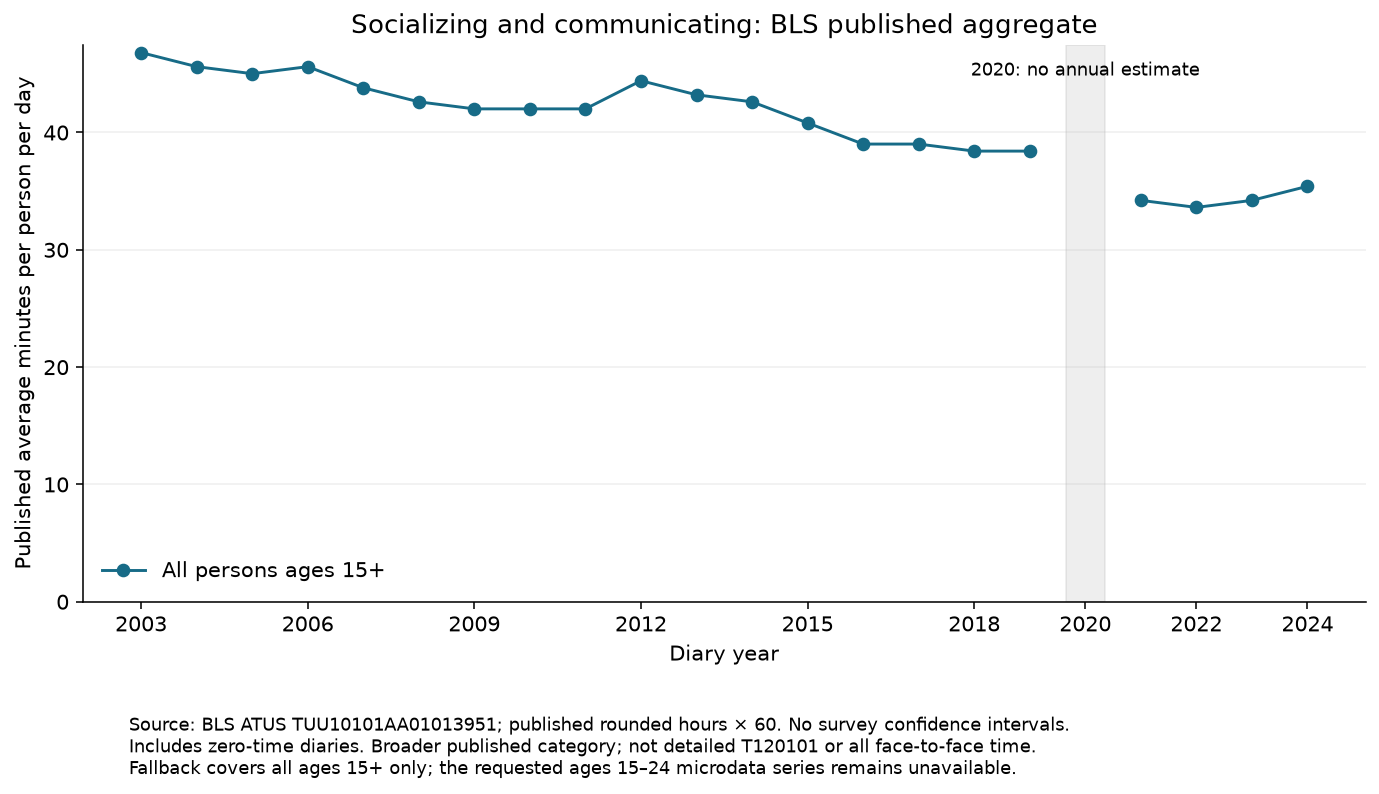

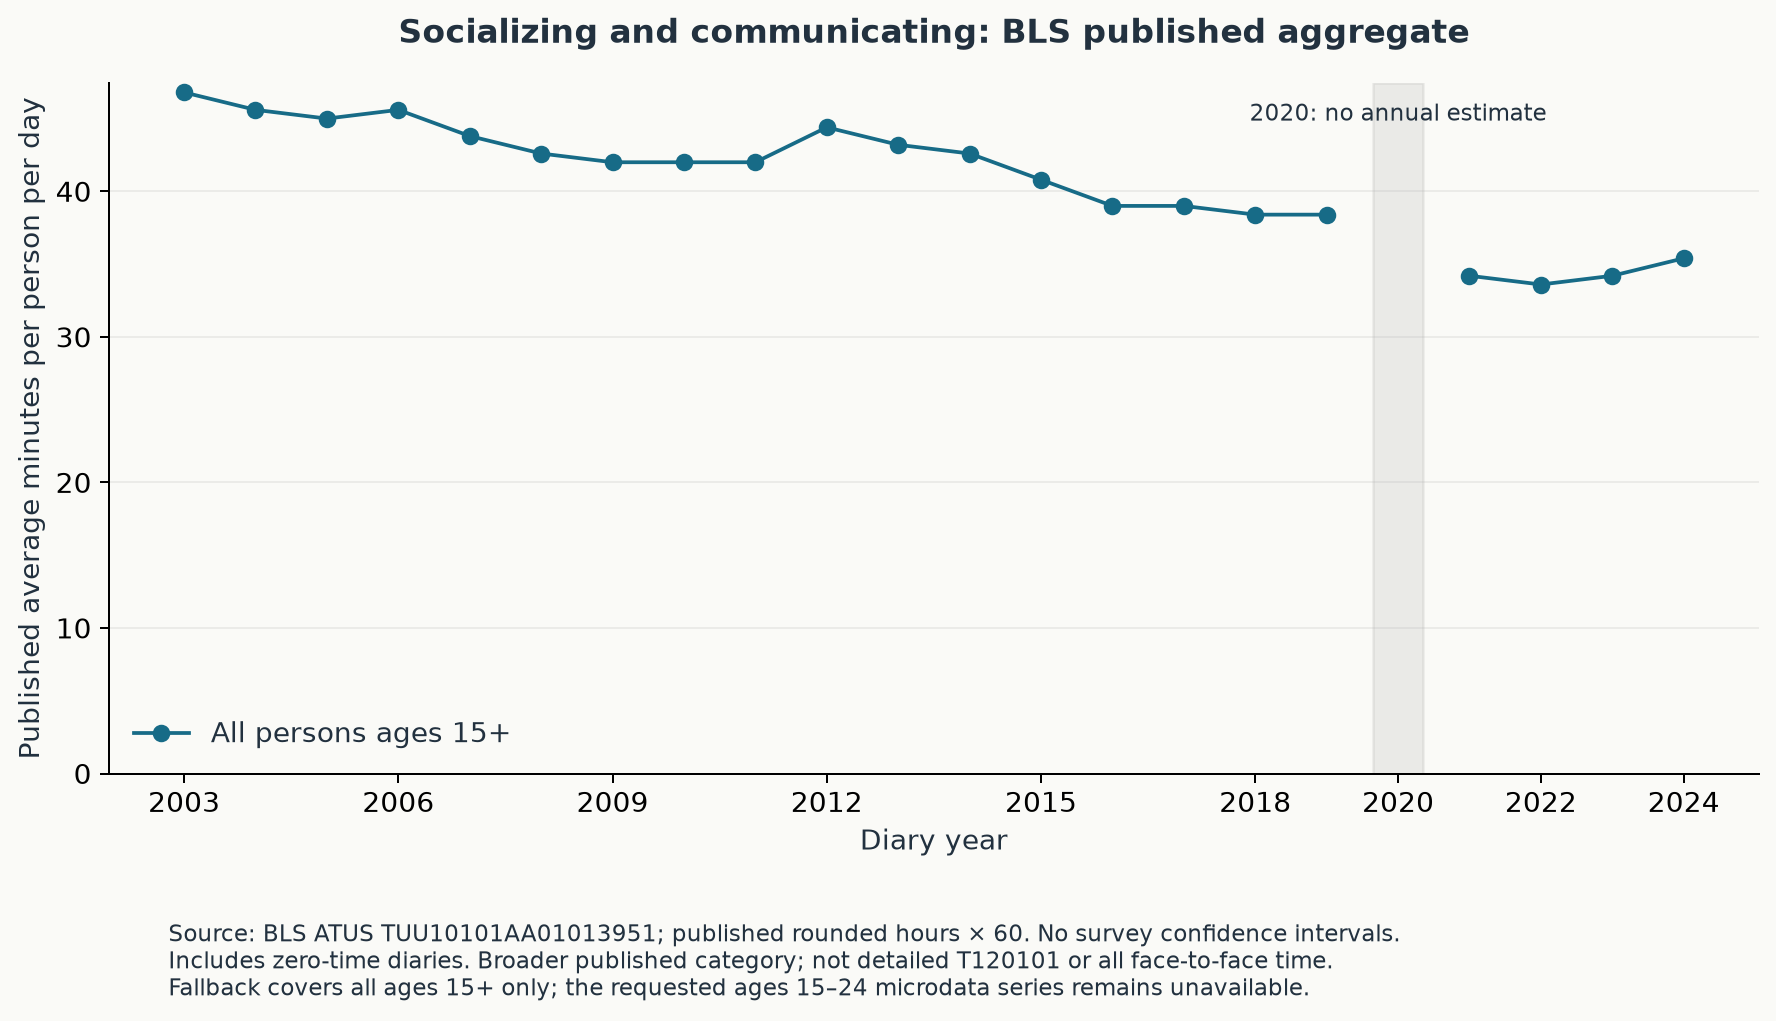

In [3]:
figure = socializing_module.plot_trends(annual)
show_figure(figure)
plt.close(figure)
show_png(figure_name)

### Descriptive changes calculated from the loaded series

In [4]:
observed = annual.loc[annual.year.ne(2020) & annual.minutes_per_day.notna()].sort_values("year")
changes = []
for age_group, series in observed.groupby("age_group", sort=False):
    first, last = series.iloc[0], series.iloc[-1]
    changes.append({"age_group": age_group, "start_year": int(first.year), "end_year": int(last.year),
                    "start_minutes_per_day": first.minutes_per_day, "end_minutes_per_day": last.minutes_per_day,
                    "change_minutes_per_day": last.minutes_per_day - first.minutes_per_day})
display(pd.DataFrame(changes))

,age_group,start_year,end_year,start_minutes_per_day,end_minutes_per_day,change_minutes_per_day
0,15+,2003,2024,46.8,35.4,-11.4


### Inspect fitted residuals and shared estimation code

,year,age_group,model,observed_minutes_per_day,fitted_minutes_per_day,residual
0,2003,15+,2003-2024_excluding_2020_descriptive,46.8,46.8498,-0.0498
1,2004,15+,2003-2024_excluding_2020_descriptive,45.6,46.2645,-0.6645
2,2005,15+,2003-2024_excluding_2020_descriptive,45.0,45.6793,-0.6793
3,2006,15+,2003-2024_excluding_2020_descriptive,45.6,45.0940,0.5060
4,2007,15+,2003-2024_excluding_2020_descriptive,43.8,44.5088,-0.7088
5,2008,15+,2003-2024_excluding_2020_descriptive,42.6,43.9235,-1.3235
6,2009,15+,2003-2024_excluding_2020_descriptive,42.0,43.3382,-1.3382
7,2010,15+,2003-2024_excluding_2020_descriptive,42.0,42.7530,-0.7530
8,2011,15+,2003-2024_excluding_2020_descriptive,42.0,42.1677,-0.1677
9,2012,15+,2003-2024_excluding_2020_descriptive,44.4,41.5825,2.8175


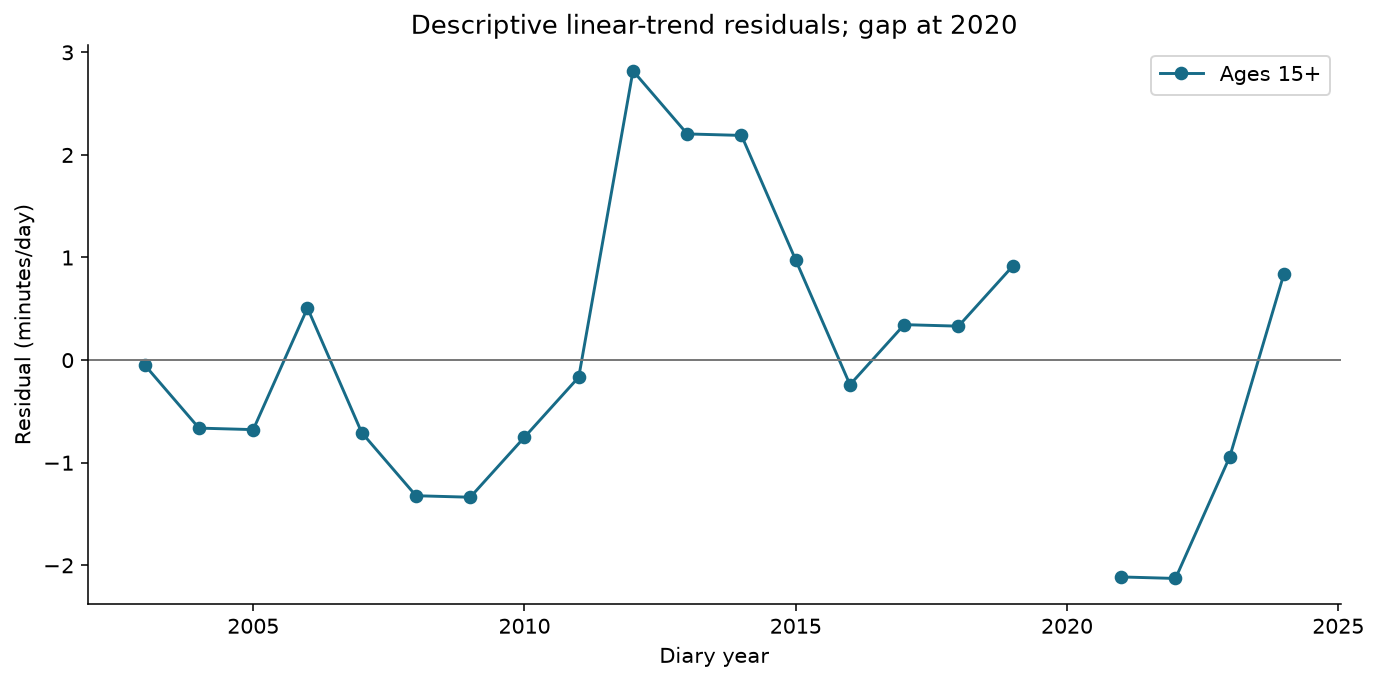

Source: `src/econhack/atus_published.py`. Functions below are displayed, not invoked.

def fit_trends(annual):
    """Describe rounded published levels with OLS; deliberately report no inference."""
    sample = annual.loc[annual.year.ne(2020)].sort_values("year")
    if sample.year.tolist() != [year for year in YEARS if year != 2020]:
        raise ValueError("Descriptive trend requires complete non-2020 calendar-year coverage")
    values = sample.minutes_per_day.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Nonfinite published annual minutes")
    design = np.column_stack([np.ones(len(sample)), sample.year.to_numpy() - 2003])
    parameters = np.linalg.lstsq(design, values, rcond=None)[0]
    prediction = design @ parameters
    residual = values - prediction
    total_variation = np.square(values - values.mean()).sum()
    explained = 1 - np.square(residual).sum() / total_variation if total_variation > 0 else np.nan
    coefficients = pd.DataFrame([{
        "model": MODEL, "age_group": "15+", "term": term, "estimate": float(parameters[position]),
        "units": "minutes/day" if position == 0 else "minutes/day per calendar year",
        "n_years": len(sample), "df_resid": len(sample) - 2, "r_squared": explained,
        "rmse_minutes_per_day": float(np.sqrt(np.mean(np.square(residual)))),
        "start_year": 2003, "end_year": 2024, "excluded_years": "2020",
        "inference_scope": "Descriptive only; no standard errors, p-values, or confidence intervals",
        "series_id": SERIES_ID, "activity_label": LABEL,
    } for position, term in enumerate(("intercept", "year_since_2003"))])
    fitted = pd.DataFrame({
        "year": sample.year.to_numpy(), "age_group": "15+", "model": MODEL,
        "observed_minutes_per_day": values, "fitted_minutes_per_day": prediction, "residual": residual,
    })
    return coefficients, fitted

def plot_trends(annual):
    import matplotlib.pyplot as plt

    series = annual.set_index("year").reindex(YEARS)
    minutes = series.minutes_per_day.copy()
    minutes.loc[2020] = np.nan
    figure, axis = plt.subplots(figsize=(10, 5.8))
    axis.plot(YEARS, minutes, marker="o", color="#176b87", label="All persons ages 15+")
    axis.axvspan(2019.65, 2020.35, color="#777777", alpha=0.12)
    axis.text(2020, 0.97, "2020: no annual estimate", transform=axis.get_xaxis_transform(),
              ha="center", va="top", fontsize=9)
    axis.set(title="Socializing and communicating: BLS published aggregate",
             xlabel="Diary year", ylabel="Published average minutes per person per day", ylim=(0, None))
    axis.set_xticks([2003, 2006, 2009, 2012, 2015, 2018, 2020, 2022, 2024])
    axis.grid(axis="y", alpha=0.2)
    axis.legend(frameon=False, loc="lower left")
    figure.text(0.1, 0.035,
                f"Source: BLS ATUS {SERIES_ID}; published rounded hours × 60. No survey confidence intervals.\n"
                "Includes zero-time diaries. Broader published category; not detailed T120101 or all face-to-face time.\n"
                "Fallback covers all ages 15+ only; the requested ages 15–24 microdata series remains unavailable.", fontsize=9)
    figure.tight_layout(rect=(0, 0.14, 1, 1))
    return figure

In [5]:
display(fitted.head(12))
figure, axis = plt.subplots()
descriptive = fitted.loc[fitted.model.str.contains("descriptive")]
for label, series in descriptive.groupby("age_group"):
    series = series.set_index("year").reindex(range(2003, 2025))
    axis.plot(series.index, series.residual, marker="o", label=f"Ages {label}")
axis.axhline(0, color="#777777", linewidth=1)
axis.set(xlabel="Diary year", ylabel="Residual (minutes/day)", title="Descriptive linear-trend residuals; gap at 2020")
axis.legend()
figure.tight_layout()
show_figure(figure)
plt.close(figure)
show_source(socializing_module.__name__, ["fit_trends", "plot_trends"])

## Interpretation and limits

This is primary-activity socializing/communicating, not total face-to-face time or an individual loneliness outcome. Published levels are rounded by BLS. There is no 2020 full-year estimate. Youth results require actual youth microdata. The full-period regression is descriptive; any pre-pandemic HAC inference in the microdata model is temporal uncertainty, not survey-design uncertainty. Do not interpret these trends as effects of a particular technology or policy.

## Inputs used

Exact local inputs and SHA-256 hashes for this execution. These receipts identify table/figure versions; they are not an independent validation of their statistical content.

In [6]:
display(pd.DataFrame(input_receipts).drop_duplicates().reset_index(drop=True))

,path,sha256
0,outputs/model_status.json,1c0591b04c884482be94eb86e682158fbfd08cc0a5f4fc...
1,data/processed/atus_published_annual.csv,85c3e8148fe4c8fd30f9f6dcc16bdfa3907701250ce717...
2,outputs/tables/atus_published_regression.csv,10f4947734f0eb022fb3b975ab246fe674e7cadd0308c2...
3,outputs/tables/atus_published_fitted.csv,3c3b136b78b457ab9702f8d54a090c8c8b958688c976cd...
4,outputs/figures/atus_published_trend.png,ca9b207a1268f386495d481006e9b0d49b82590b921125...
